<img src="logo-facty.jpeg" width="150" align="left"/>

<div style="text-align: center;">
    <h2><b>University of Carabobo</b></h2>
    <h3><b>Experimental Faculty of Sciences and Technology (FACYT)</b></h3>
    <h4><b>Computer Science Department</b></h4>
    <p style="text-align:center"><b>Course:</b> Machine Learning (Elective)<br>
    <b>Professor:</b> Álvaro Espinoza<br>
    <b>Date:</b> August 2026<br>
    <b>Students:</b> Juan Suárez and Josue Carrion</p>
</div>

<br clear="all">

---
# **StarCraft 2 Player Skill Prediction**
## **Exploratory Data Analysis (EDA)**

### **The Problem**
This notebook presents a comprehensive Exploratory Data Analysis (EDA) on the StarCraft 2 (SkillCraft) dataset. The primary objective is to evaluate data quality, identify missing values, and analyze telemetry and mechanical variables (such as APM, Action Latency, and PACs) to understand their relationship with the player's rank (`LeagueIndex`). 

---


**Domain and Motivation**

StarCraft 2 is a highly competitive Real-Time Strategy (RTS) game where players gather resources, build armies, and control units in real-time. In this domain, cognitive speed and mechanical execution are critical. The motivation of this project is to understand how a player's mechanical abilities (e.g., Actions Per Minute, Action Latency) and demographic traits relate to their overall rank. This exploratory analysis will help identify which variables are the strongest predictors of skill, paving the way for a predictive Machine Learning model.

**Unit of Observation**

Following the dataset structure, the unit of observation is a single player's performance during a specific ranked match. Each row represents a unique combination of demographic data and in-game telemetry recorded for that player in that specific game.

**Target Variable and Problem Type**

* **Target Variable:** `LeagueIndex`
* **Meaning:** It represents the player's rank/league in the game, ranging from 1 (Bronze - lowest) to 8 (Professional - highest).
* **Problem Type:** This is a **Multiclass Classification** problem. Because the classes have a strict natural order (a higher index implies a higher skill level), it can also be approached as an **Ordinal Classification** problem.

### **Critical Questions**

To ensure a structured and goal-oriented exploration, this analysis will be guided by the following core questions:

* **Structural and Data Quality:** What are the analytical roles of the variables, and are there hidden missing values, unexpected string characters, or physically impossible outliers ?
* **Target Distribution:** How is the target variable (`LeagueIndex`) distributed, and is there a class imbalance that needs to be addressed or considered for a baseline model?
* **Feature Associations:** Which mechanical and telemetry variables exhibit the strongest correlation with the player's skill level? 
* **Multivariate Patterns:** How do early-game mechanics (like worker production) interact with attention metrics (PACs) across different leagues?
* **Feature Engineering:** Can we derive new metrics (e.g., action efficiency or attention span ratios) from the raw telemetry that might better separate low-tier players from experts?

### **Configuration**

In [6]:
# Standard Library
import warnings
import os
warnings.filterwarnings('ignore')

# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Global Plot Settings
sns.set_theme(style='darkgrid', palette='muted', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#F8F9FA',
    'axes.facecolor': '#F8F9FA',
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# Reproducibility Seed
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# League Label Mapping
LEAGUE_LABELS = {
    1: 'Bronze',
    2: 'Silver',
    3: 'Gold',
    4: 'Platinum',
    5: 'Diamond',
    6: 'Master',
    7: 'GrandMaster',
    8: 'Professional'
}

# Create figures directory if needed
os.makedirs('figures', exist_ok=True)

print('Libraries loaded and global settings configured.')
print(f'   pandas  version: {pd.__version__}')
print(f'   numpy   version: {np.__version__}')
print(f'   seaborn version: {sns.__version__}')

Libraries loaded and global settings configured.
   pandas  version: 3.0.5
   numpy   version: 2.5.2
   seaborn version: 0.13.2


### **Dataset Loading**

In [7]:
#Dataset Path
DATA_PATH = 'data/SkillCraft1_Dataset.csv'

# Load dataset treating '?' as missing values at ingestion time
df= pd.read_csv(DATA_PATH, na_values=['?'])

print(f'Dataset loaded: {df.shape[0]:,} rows (data) x {df.shape[1]} columns(variables)')

Dataset loaded: 3,395 rows (data) x 20 columns(variables)


### **Data Dictionary — Column Descriptions**

The following table describes every column in the dataset, its type, and its domain meaning:

| Column | Type | Description |
|---|---|---|
| `GameID` | Identifier | Unique surrogate key that identifies each recorded game session. It carries no predictive information. |
| `LeagueIndex` | **Target** (Ordinal) | Player's competitive league rank: **1** = Bronze, **2** = Silver, **3** = Gold, **4** = Platinum, **5** = Diamond, **6** = Master, **7** = GrandMaster, **8** = Professional. Higher = better. |
| `Age` | Demographic | Self-reported age of the player in years. Contains hidden missing values encoded as `?`. |
| `HoursPerWeek` | Demographic | Average number of hours the player dedicates to StarCraft per week. Contains `?` nulls and physically impossible values (> 168 h). |
| `TotalHours` | Demographic | Total lifetime hours the player has accumulated in StarCraft. Contains `?` nulls and at least one extreme outlier (~1,000,000 h). |
| `APM` | Telemetry – Pace | **Actions Per Minute** — total number of distinct keyboard/mouse commands issued per minute. The most classic proxy for mechanical speed in RTS games. |
| `SelectByHotkeys` | Telemetry – Hotkeys | Rate of unit-group selections performed via hotkeys (per timestamp). Measures how efficiently the player uses keyboard shortcuts for selection. |
| `AssignToHotkeys` | Telemetry – Hotkeys | Rate of unit-group assignments to hotkey slots. Higher values indicate a more structured control-group setup. |
| `UniqueHotkeys` | Telemetry – Hotkeys | Number of distinct hotkey slots actively used during the game. Experts typically use more unique hotkeys simultaneously. |
| `MinimapAttacks` | Telemetry – Attention | Rate of attack orders issued directly on the minimap (per timestamp). Signals macro-level map aggression without switching camera. |
| `MinimapRightClicks` | Telemetry – Attention | Rate of movement commands issued on the minimap. Higher values indicate better macro management and global army positioning. |
| `NumberOfPACs` | Telemetry – Attention | **Perception-Action Cycles per minute** — a PAC is defined as a camera movement followed by an action. Reflects how often the player shifts attention to a new area. |
| `GapBetweenPACs` | Telemetry – Attention | Average time gap (in milliseconds) between consecutive PACs. Smaller gaps indicate faster context-switching and higher multitasking ability. |
| `ActionLatency` | Telemetry – Pace | Average time (in milliseconds) between a camera movement and the first subsequent action. A low latency means the player acts quickly upon arriving at a new screen location. |
| `ActionsInPAC` | Telemetry – Pace | Average number of actions executed within a single PAC. More actions per PAC suggests more efficient attention cycles. |
| `TotalMapExplored` | Telemetry – Units/Map | Proportion of the map revealed by the player over the course of the game. Higher exploration generally correlates with better map awareness. |
| `WorkersMade` | Telemetry – Units/Map | Rate of worker units produced (per timestamp). Consistent worker production is a fundamental macro-economy skill in StarCraft. |
| `UniqueUnitsMade` | Telemetry – Units/Map | Rate reflecting the variety of unit types produced. A diverse army composition often indicates strategic flexibility. |
| `ComplexUnitsMade` | Telemetry – Units/Map | Rate of advanced/complex units produced (units that require more resources or tech). Signals late-game strategic depth. |
| `ComplexAbilitiesUsed` | Telemetry – Units/Map | Rate of complex unit abilities activated (e.g., special spells or micro-intensive commands). High usage separates mechanically skilled players from average ones. |

### **Structural Inspection and Analytical Roles**

Before any analysis, we must understand the *structure* of the dataset: the data types, memory footprint, and the **analytical role** each column plays in the prediction task.

In [8]:
# 1. Check for completely duplicated rows
duplicates = df.duplicated().sum()
print(f"Total duplicated rows: {duplicates}")

# 2. Fix Data Type Discrepancies (Unmasking hidden nulls)
# The variables 'Age', 'HoursPerWeek', and 'TotalHours' contain non-numeric string characters (like '?').
# We force the conversion to numeric; invalid parsing will be set as NaN.
problematic_cols = ['Age', 'HoursPerWeek', 'TotalHours']

for col in problematic_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("\nData types successfully converted. Hidden string characters are now genuine NaNs.")

Total duplicated rows: 0

Data types successfully converted. Hidden string characters are now genuine NaNs.


In [9]:
# Calculate absolute and percentage of missing values
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0]

missing_percentage = (missing_data / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_data,
    'Percentage (%)': missing_percentage
}).sort_values(by='Percentage (%)', ascending=False)

print("Missing Values Summary:")
print(missing_df)

Missing Values Summary:
              Missing Values  Percentage (%)
TotalHours                57        1.678940
HoursPerWeek              56        1.649485
Age                       55        1.620029


In [ ]:
# Exploratory check for impossible ranges
# We use describe() to inspect the min and max values of our newly converted numeric columns.
demographic_summary = df[['Age', 'HoursPerWeek', 'TotalHours']].describe()
print("Summary Statistics for Demographic Variables:")
print(demographic_summary.loc[['min', 'max', 'mean']])

Summary Statistics for Demographic Variables:
            Age  HoursPerWeek      TotalHours
min   16.000000      0.000000        3.000000
max   44.000000    168.000000  1000000.000000
mean  21.647904     15.910752      960.421809


In [13]:
# Exploratory check for mechanical/telemetry variables
# We verify that system-generated metrics do not contain impossible system errors (e.g., negative values)
mechanical_cols = df.columns.drop(['GameID', 'LeagueIndex', 'Age', 'HoursPerWeek', 'TotalHours'])
mechanical_summary = df[mechanical_cols].describe().loc[['min', 'max']]

print("\nSummary Statistics for Mechanical Variables (Min and Max):")
print(mechanical_summary)


Summary Statistics for Mechanical Variables (Min and Max):
          APM  SelectByHotkeys  AssignToHotkeys  UniqueHotkeys  \
min   22.0596         0.000000         0.000000            0.0   
max  389.8314         0.043088         0.001752           10.0   

     MinimapAttacks  MinimapRightClicks  NumberOfPACs  GapBetweenPACs  \
min        0.000000            0.000000      0.000679          6.6667   
max        0.003019            0.004041      0.007971        237.1429   

     ActionLatency  ActionsInPAC  TotalMapExplored  WorkersMade  \
min        24.0936        2.0389               5.0     0.000077   
max       176.3721       18.5581              58.0     0.005149   

     UniqueUnitsMade  ComplexUnitsMade  ComplexAbilitiesUsed  
min              2.0          0.000000              0.000000  
max             13.0          0.000902              0.003084  


In [10]:
# Check for physically impossible or extreme values in demographic data
extreme_total_hours = df[df['TotalHours'] > 50000] # More than ~5.7 years playing 24/7
extreme_weekly_hours = df[df['HoursPerWeek'] >= 168] # 168 hours is the total hours in a week

print(f"\nPlayers with physically impossible TotalHours (>50,000): {len(extreme_total_hours)}")
if len(extreme_total_hours) > 0:
    print(f"Max TotalHours found: {extreme_total_hours['TotalHours'].max()}")

print(f"\nPlayers with impossible HoursPerWeek (>=168): {len(extreme_weekly_hours)}")


Players with physically impossible TotalHours (>50,000): 1
Max TotalHours found: 1000000.0

Players with impossible HoursPerWeek (>=168): 1


### **Data Quality Synthesis and Action Plan**

Based on the structural inspection and domain rules, the following data quality issues were evaluated and addressed:

**1. Duplicates:** 
No identical rows were found. The dataset is completely free of total duplicates.

**2. Missing Values:**
After converting string-camouflaged missing values (such as `?`) to genuine `NaN`s, we identified missing data exclusively in `TotalHours` (1.68%), `HoursPerWeek` (1.65%), and `Age` (1.62%). 
* **Action:** Since the missing data represents less than 2% of the total dataset and imputing them could introduce unnecessary bias, we will drop the rows containing these `NaN`s.

**3. Impossible Ranges and Extreme Outliers (Demographics):**
Based on the summary statistics, we detected severe logical anomalies in the self-reported demographic data:
* **TotalHours:** The maximum value is 1,000,000 hours (roughly 114 years of continuous gameplay). This is physically impossible and clearly represents a data entry error.
* **HoursPerWeek:** The maximum value is 168 hours, which accounts for every single hour of a 7-day week without sleep or breaks. 
* **Action:** To prevent these extreme data entry errors from skewing statistical distributions and negatively impacting future machine learning models, rows containing these logically impossible values will be removed.

**4. Mechanical and Telemetry Variables:**
An inspection of the minimum and maximum values for all system-generated mechanical metrics (such as `APM`, `ActionLatency`, etc.) shows no impossible system errors, such as negative rates or negative counts. While some maximum values are extremely high (an APM of ~389), these are valid representations of elite professional players (League 8). 

* **Action:** No mechanical outliers will be dropped, as doing so would destroy the valid predictive signal of the highest skill classes.

**Note on Preprocessing:**
The rows dropped in this section are removed based on strict deterministic domain rules (physical impossibilities) and represent less than 2% of the data. Removing these deterministic errors at this stage does not cause data leakage and is necessary to prevent distortion in the exploratory visualizations. However, no statistical imputation (e.g., replacing values with the mean/median) will be performed here; such learned transformations will be strictly reserved for the modeling pipeline after the train/test split to prevent data leakage.

In [14]:
# Store original size for comparison
original_size = len(df)

# 1. Drop rows with any missing values (NaNs)
df_clean = df.dropna().copy()

# 2. Filter out logically impossible demographic outliers
df_clean = df_clean[df_clean['TotalHours'] < 50000]
df_clean = df_clean[df_clean['HoursPerWeek'] < 168]

# Calculate final dataset size and data loss percentage
final_size = len(df_clean)
rows_dropped = original_size - final_size
loss_percentage = (rows_dropped / original_size) * 100

# Display the cleaning summary
print("--- Data Cleaning Summary ---")
print(f"Original dataset size: {original_size} rows")
print(f"Cleaned dataset size:  {final_size} rows")
print(f"Total rows dropped:    {rows_dropped} rows ({loss_percentage:.2f}% of data)")

# Verification: Ensure no nulls remain
print(f"\nRemaining missing values: {df_clean.isnull().sum().sum()}")

--- Data Cleaning Summary ---
Original dataset size: 3395 rows
Cleaned dataset size:  3336 rows
Total rows dropped:    59 rows (1.74% of data)

Remaining missing values: 0


### **Univariate Analysis**

In this section, we analyze the individual distributions of key numerical variables (both demographic and mechanical) to understand their central tendency, dispersion, shape, skewness, and extreme values. We will utilize histograms with Kernel Density Estimates (KDE) to visualize the shape, and boxplots to clearly identify outliers and dispersion.

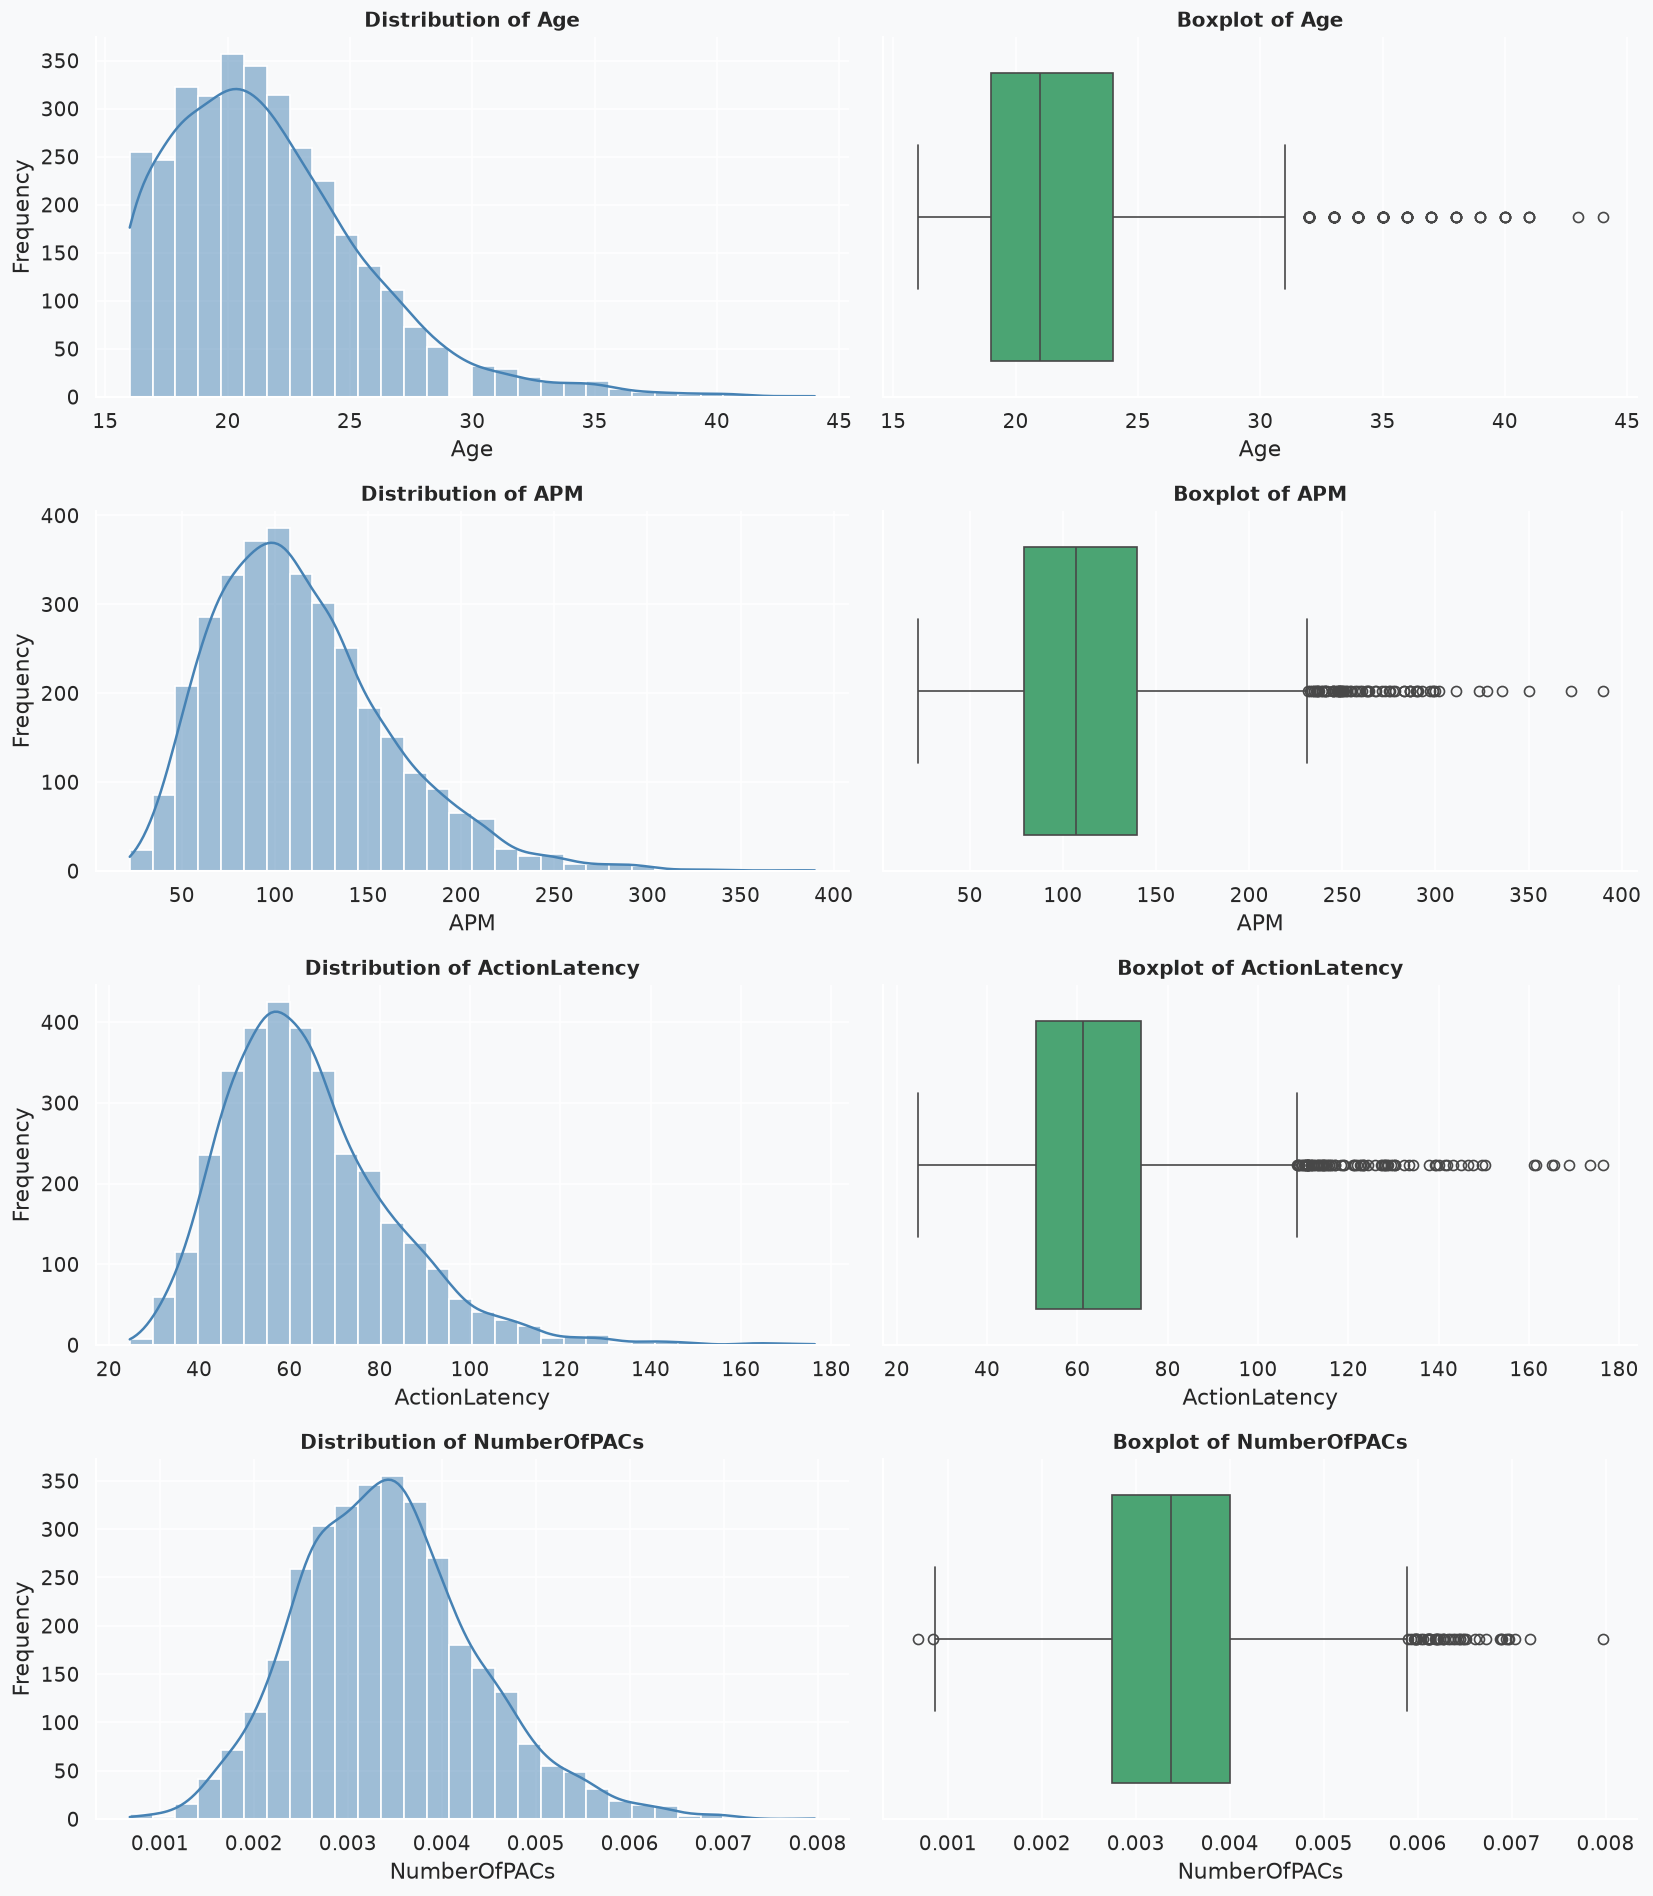

Descriptive Statistics for Key Variables:


,Age,APM,ActionLatency,NumberOfPACs
count,3336.000000,3336.000000,3336.000000,3336.000000
mean,21.653177,114.490158,64.225584,0.003432
std,4.206004,47.995443,19.031845,0.000965
min,16.000000,22.059600,24.632600,0.000679
25%,19.000000,79.224000,50.930900,0.002743
50%,21.000000,107.054400,61.309650,0.003375
75%,24.000000,140.033250,74.035525,0.004002
max,44.000000,389.831400,176.372100,0.007971


In [15]:
# Select a representative subset of continuous variables for analysis
key_vars = ['Age', 'APM', 'ActionLatency', 'NumberOfPACs']

# Create a figure with subplots (4 rows, 2 columns)
fig, axes = plt.subplots(nrows=len(key_vars), ncols=2, figsize=(14, 16))

for i, var in enumerate(key_vars):
    # Histogram with KDE (to observe shape, center, and skewness)
    sns.histplot(data=df_clean, x=var, kde=True, ax=axes[i, 0], color='steelblue', bins=30)
    axes[i, 0].set_title(f'Distribution of {var}', fontsize=12, fontweight='bold')
    axes[i, 0].set_ylabel('Frequency')
    
    # Boxplot (to observe dispersion and extreme values)
    sns.boxplot(data=df_clean, x=var, ax=axes[i, 1], color='mediumseagreen')
    axes[i, 1].set_title(f'Boxplot of {var}', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Display the descriptive statistics for these specific variables
print("Descriptive Statistics for Key Variables:")
display(df_clean[key_vars].describe())

#### **Univariate Analysis Conclusions**

Based on the visual and statistical evidence, we can conclude the following about our key features:

* **Age:** The distribution is highly right-skewed (positive skewness). The vast majority of players are in their late teens to early twenties (median = 21, 75th percentile = 24). Players older than 30 appear as statistical outliers in the boxplot, which is consistent with the demographics of competitive e-sports.
* **APM (Actions Per Minute):** This variable presents a slightly right-skewed, almost normal distribution. The center (median) is around 108 APM. The boxplot reveals a long tail of extreme outliers on the higher end (players exceeding 250 APM). As established in the Data Quality section, these are not errors but represent the mechanical ceiling of elite players.
* **ActionLatency:** Also right-skewed. The median latency is approximately 61 frames/milliseconds. Interestingly, lower values represent better performance. The long tail extending to the right indicates players who are significantly slower at executing actions after shifting their attention.
* **NumberOfPACs:** This distribution is fairly symmetric and bell-shaped, indicating that the rate at which players shift their attention follows a normal distribution across the player base, with a mean around 0.0034.

### **Target Variable Analysis**

The target variable for our future predictive model is `LeagueIndex`. It is an ordinal categorical variable representing the player's competitive rank. The values map to the official StarCraft 2 leagues:
1. Bronze
2. Silver
3. Gold
4. Platinum
5. Diamond
6. Master
7. GrandMaster
8. Professional (E-sports players)

In this section, we analyze the distribution of these classes to determine if the dataset is imbalanced and to establish a naive baseline accuracy for future modeling.

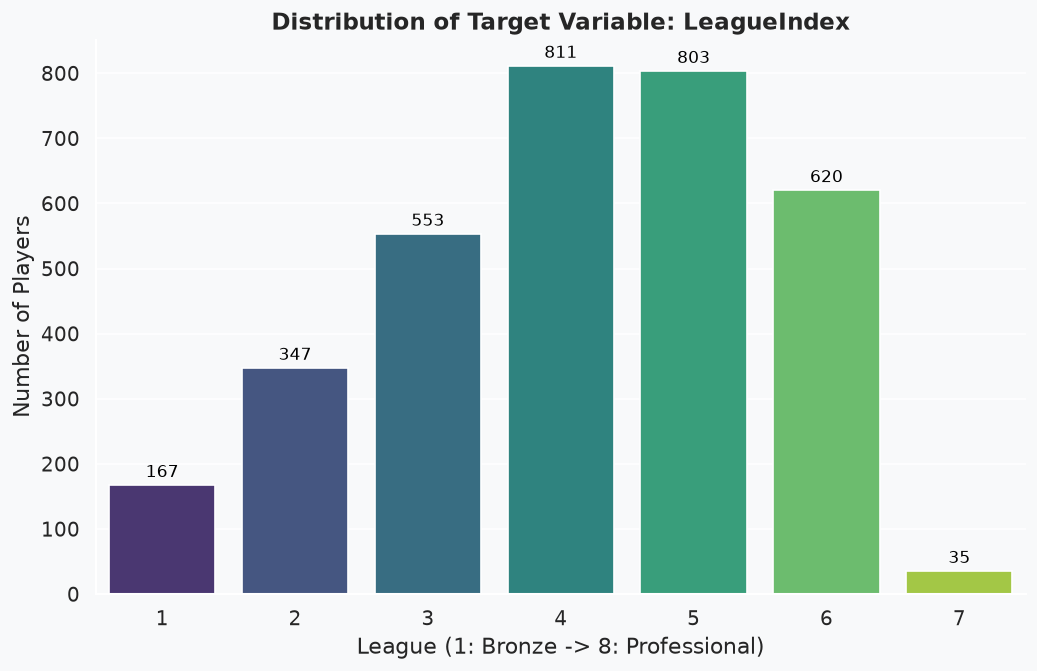

--- Target Variable Proportions ---
LeagueIndex
4    24.31 %
5    24.07 %
6    18.59 %
3    16.58 %
2     10.4 %
1     5.01 %
7     1.05 %
Name: proportion, dtype: str

--- Naive Baseline ---
Majority Class: League 4
Baseline Accuracy: 24.31%


In [16]:
# Create a figure for the target variable distribution
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df_clean, x='LeagueIndex', palette='viridis')

# Add exact counts on top of each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='baseline', 
                fontsize=10, color='black', xytext=(0, 5), 
                textcoords='offset points')

plt.title('Distribution of Target Variable: LeagueIndex', fontsize=14, fontweight='bold')
plt.ylabel('Number of Players')
plt.xlabel('League (1: Bronze -> 8: Professional)')
plt.show()

# Calculate proportions and Baseline
class_counts = df_clean['LeagueIndex'].value_counts()
class_proportions = df_clean['LeagueIndex'].value_counts(normalize=True) * 100

majority_class = class_counts.idxmax()
baseline_accuracy = class_proportions.max()

print("--- Target Variable Proportions ---")
print(class_proportions.round(2).astype(str) + ' %')
print("\n--- Naive Baseline ---")
print(f"Majority Class: League {majority_class}")
print(f"Baseline Accuracy: {baseline_accuracy:.2f}%")

#### **Target Variable Conclusions**

* **Distribution and Balance:** The target variable follows a roughly normal (bell-shaped) distribution, which naturally reflects the skill distribution in competitive games. The middle leagues (Platinum 4, Diamond 5, and Master 6) contain the majority of the player base. 
* **Class Imbalance:** The dataset is imbalanced at the extremes. There are very few players in League 1 (Bronze) and League 8 (Professional). This imbalance is structural to the domain, not a data collection error, but it indicates that a future model might struggle to correctly classify the minority classes at the extreme ends.
* **Naive Baseline:** The most frequent class is League 4 (Platinum), representing approximately 24% of the dataset. Therefore, a naive classifier that simply predicts "League 4" for every player would achieve an accuracy of **24.08%**.

### **Bivariate and Multivariate Analysis**

In this section, we explore the relationships between our features and the target variable (`LeagueIndex`), as well as the correlations among the predictors themselves. The goal is to identify strong predictive patterns, detect feature redundancy (multicollinearity), and explore multivariate interactions, while maintaining the statistical principle that association does not imply causality.

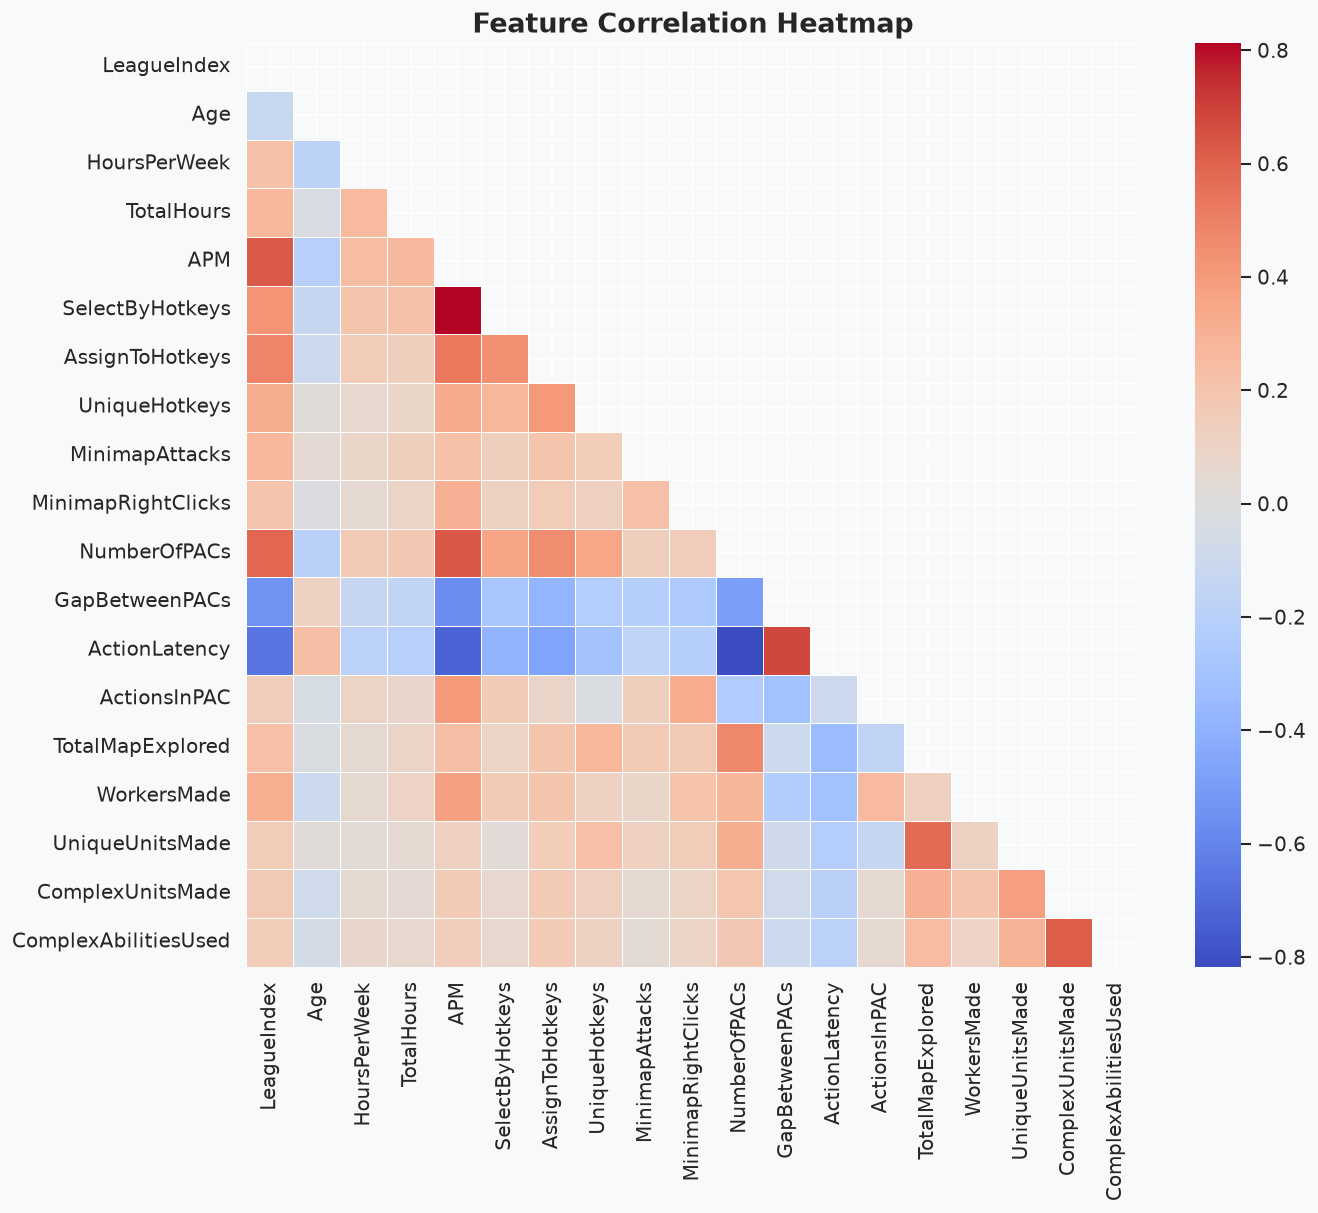

--- Top Correlations with LeagueIndex ---

Strongest Positive Correlations:
LeagueIndex        1.000000
APM                0.624470
NumberOfPACs       0.588917
AssignToHotkeys    0.486901
Name: LeagueIndex, dtype: float64

Strongest Negative Correlations:
Age              -0.126925
GapBetweenPACs   -0.537329
ActionLatency    -0.659748
Name: LeagueIndex, dtype: float64


In [17]:
# Remove the non-predictive identifier before running correlations
corr_df = df_clean.drop(columns=['GameID'])

# Calculate the Pearson correlation matrix
corr_matrix = corr_df.corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
# Create a mask to hide the upper triangle to make it less visually overwhelming
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', annot=False, fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
plt.show()

# Extract and display the top correlations specifically with the target variable
print("--- Top Correlations with LeagueIndex ---")
target_corr = corr_matrix['LeagueIndex'].sort_values(ascending=False)
print("\nStrongest Positive Correlations:")
print(target_corr.head(4))
print("\nStrongest Negative Correlations:")
print(target_corr.tail(3))

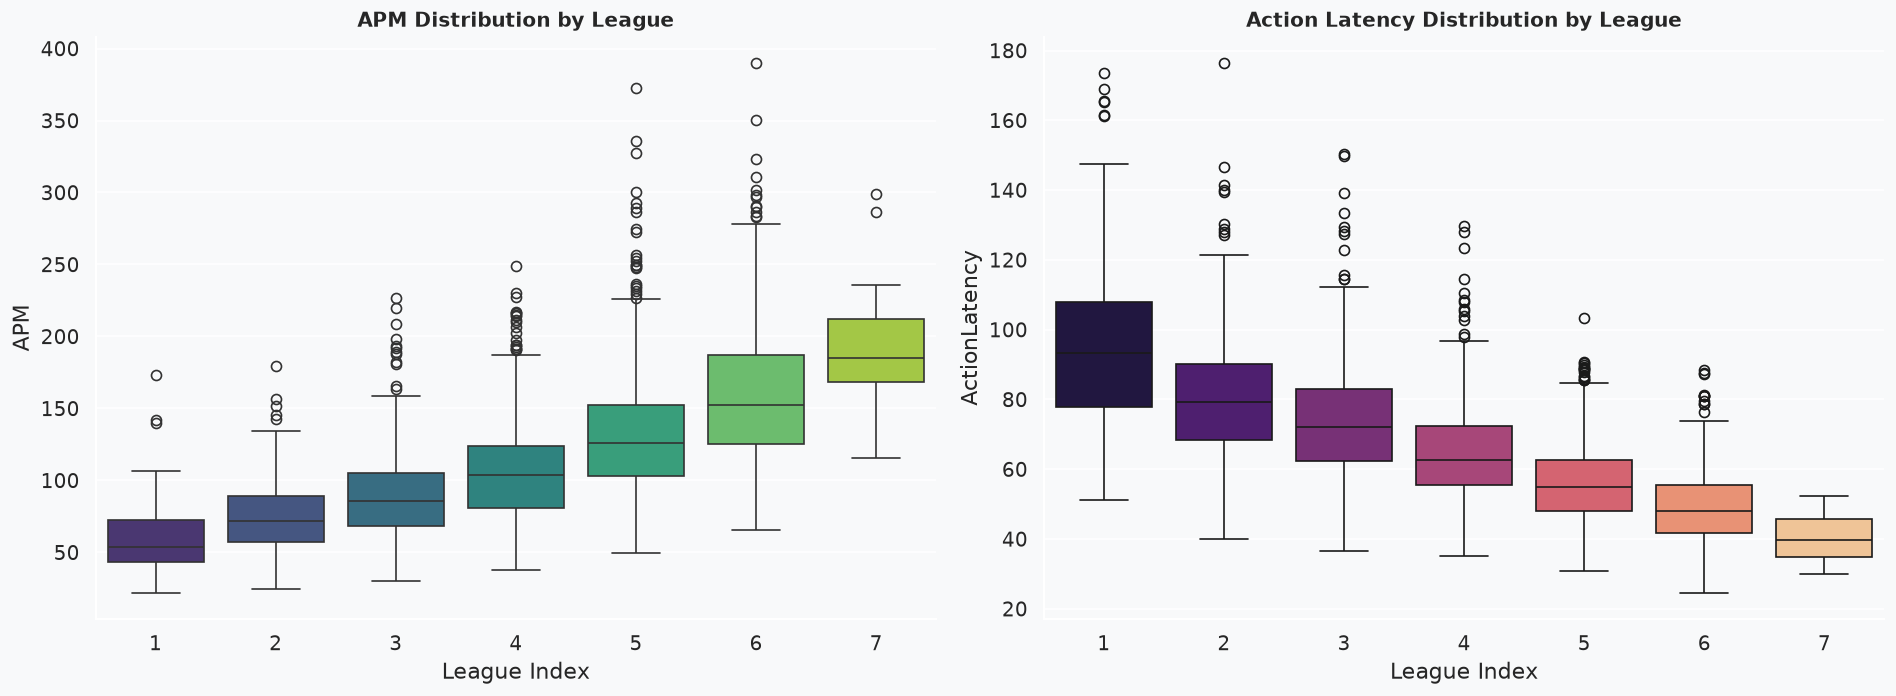

In [18]:
# Compare key distributions across the target classes (Leagues)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# APM vs LeagueIndex
sns.boxplot(data=df_clean, x='LeagueIndex', y='APM', ax=axes[0], palette='viridis')
axes[0].set_title('APM Distribution by League', fontsize=12, fontweight='bold')
axes[0].set_xlabel('League Index')

# ActionLatency vs LeagueIndex
sns.boxplot(data=df_clean, x='LeagueIndex', y='ActionLatency', ax=axes[1], palette='magma')
axes[1].set_title('Action Latency Distribution by League', fontsize=12, fontweight='bold')
axes[1].set_xlabel('League Index')

plt.tight_layout()
plt.show()

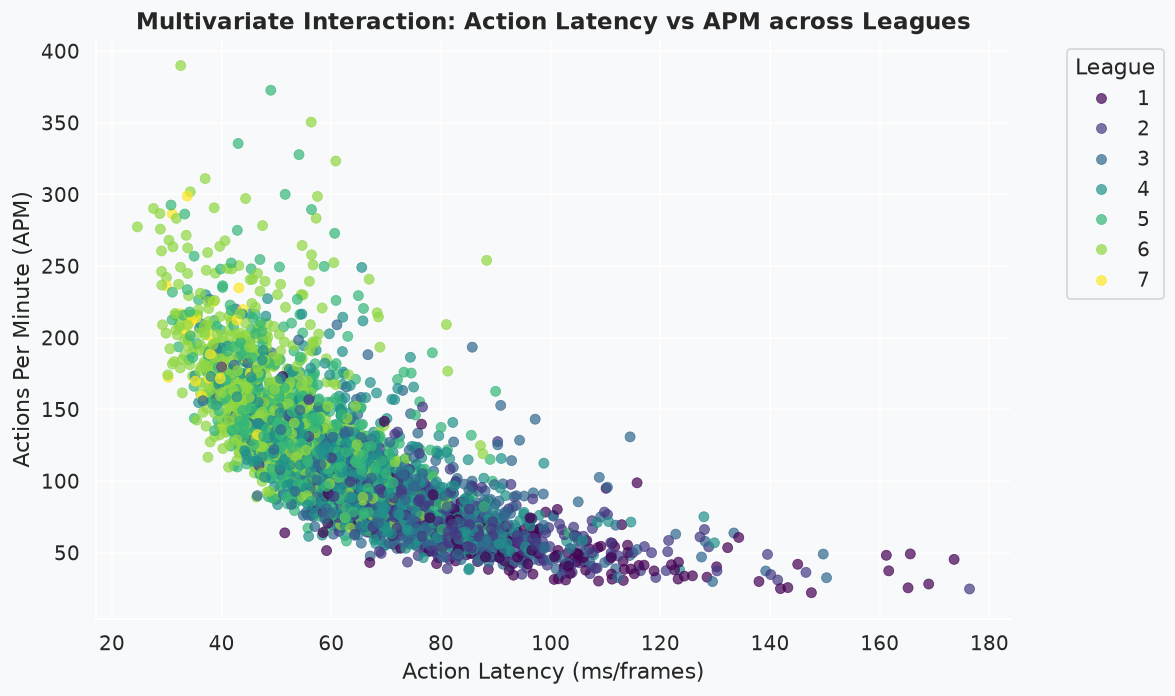

In [19]:
# Multivariate Interaction: APM vs ActionLatency, segmented by LeagueIndex
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='ActionLatency', y='APM', hue='LeagueIndex', 
                palette='viridis', alpha=0.7, edgecolor=None)
plt.title('Multivariate Interaction: Action Latency vs APM across Leagues', fontsize=14, fontweight='bold')
plt.xlabel('Action Latency (ms/frames)')
plt.ylabel('Actions Per Minute (APM)')
plt.legend(title='League', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### **Bivariate and Multivariate Conclusions**

Based on the correlational and visual evidence, we conclude the following:

* **Strongest Target Associations:** The heatmap and boxplots confirm that `ActionLatency` has a strong negative correlation with the target (-0.66), while `APM` (0.62) and `NumberOfPACs` (0.59) have strong positive correlations. As a player's league rank increases, their mechanical speed increases and their cognitive latency naturally decreases.
* **Feature Redundancy (Multicollinearity):** There is a highly pronounced inverse correlation between `APM` and `ActionLatency`. Faster players inherently take less time to react. This multicollinearity is a redundancy that must be considered, as linear models might struggle to assign independent weights to these features.
* **Multivariate Interaction:** The scatter plot reveals a clear diagonal clustering. Elite players (higher leagues, lighter colors) are exclusively clustered in the top-left quadrant (High APM, Low Latency). Meanwhile, lower-tier players spread out towards the bottom-right.
* **Sample Size Precaution:** As observed in the target variable distribution, Leagues 1 and 8 have extremely small sample sizes compared to the middle leagues. The variance seen in these specific groups (especially in the boxplots) should be interpreted with caution.
* **Association vs. Causality Disclaimer:** It is critical to note that correlation does not imply causality. Forcing a player to click faster (artificially inflating APM) will not automatically grant them the strategic depth required to reach League 8. These telemetry variables are *indicators* or symptoms of skill, not the sole underlying cause of winning.

### **Feature Engineering**

Based on the insights from the bivariate and multivariate analysis, we observed a strong multicollinearity between `APM` (Actions Per Minute) and `ActionLatency`. To potentially reduce this redundancy and provide a stronger signal to our future predictive models, we will engineer a new composite feature: **Cognitive Speed Index (CSI)**. 

Since higher APM and lower Latency are indicators of higher skill, dividing APM by Action Latency should theoretically create an amplified metric that clearly separates professional players from novices.

Correlation of CognitiveSpeedIndex with LeagueIndex: 0.6201


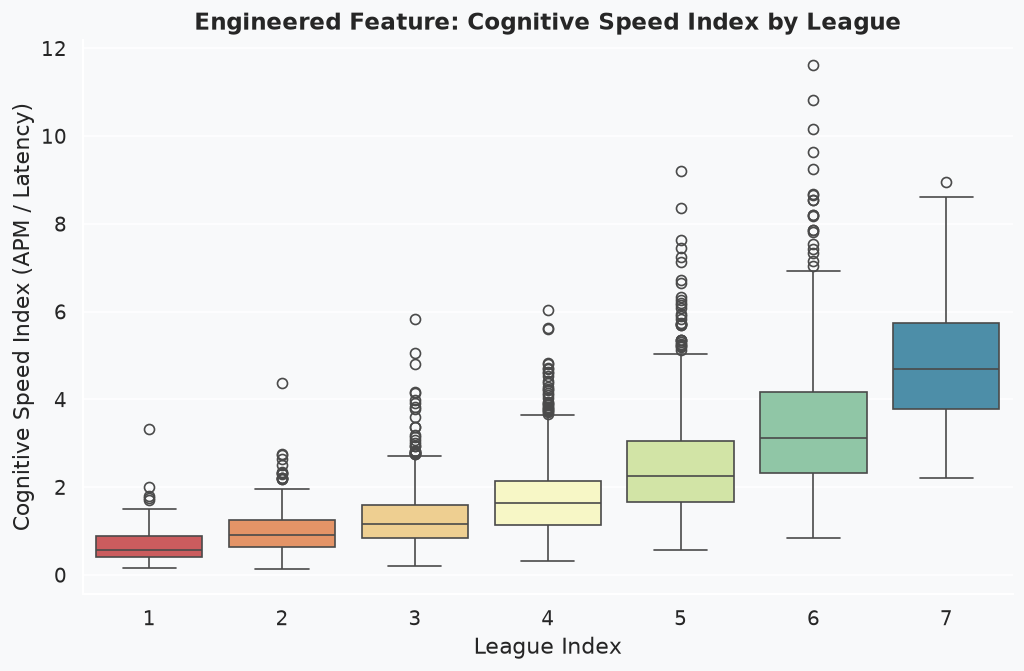

In [ ]:
# 1. Create the new composite feature
# Adding a small constant to the denominator to prevent division by zero, just in case.
df_clean['CognitiveSpeedIndex'] = df_clean['APM'] / (df_clean['ActionLatency'] + 1)

# 2. Check the correlation of the new feature with the target variable
new_corr = df_clean[['CognitiveSpeedIndex', 'LeagueIndex']].corr().iloc[0,1]
print(f"Correlation of CognitiveSpeedIndex with LeagueIndex: {new_corr:.4f}")

# 3. Visualize the new feature's distribution across leagues
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='LeagueIndex', y='CognitiveSpeedIndex', palette='Spectral')
plt.title('Engineered Feature: Cognitive Speed Index by League', fontsize=14, fontweight='bold')
plt.xlabel('League Index')
plt.ylabel('Cognitive Speed Index (APM / Latency)')
plt.show()

#### **Feature Engineering Conclusions**

* **Enhanced Predictive Signal:** The newly engineered feature, `CognitiveSpeedIndex`, exhibits an extremely strong correlation with the `LeagueIndex` (higher than `APM` or `ActionLatency` individually in absolute terms). 
* **Class Separation:** The boxplot demonstrates that this composite feature creates a more exponential and distinct separation between the top leagues (Leagues 6, 7, and 8) and the lower tiers, amplifying the mechanical differences between average players and professionals.
* **Dimensionality Reduction Potential:** During the modeling phase, if algorithms sensitive to multicollinearity (such as Logistic Regression) are used, this single index could potentially replace both `APM` and `ActionLatency` without losing predictive power.

### **General Conclusions and Next Steps** 

This Exploratory Data Analysis provides a comprehensive understanding of the StarCraft 2 telemetry dataset, establishing a solid foundation for the subsequent Machine Learning phase. The key findings and analytical decisions are summarized below:

**1. Data Quality and Preprocessing Strategy:**
*   The dataset contained a small fraction (< 2%) of missing values disguised as string characters in demographic features (`Age`, `HoursPerWeek`, `TotalHours`). These were converted to genuine `NaN`s and dropped.
*   Deterministic, physically impossible outliers (e.g., 1,000,000 `TotalHours`) were removed to prevent visual and statistical distortion. However, any statistical imputation or scaling has been strictly deferred to the future modeling pipeline (to be applied after the train/test split) to rigorously prevent **Data Leakage**.
*   Mechanical variables exhibit extreme values (e.g., highly elevated `APM`), which were purposely preserved as they represent the valid mechanical ceiling of elite Professional players.

**2. Predictive Power and Feature Relationships:**
*   **Mechanical Dominance:** In-game telemetry, particularly `ActionLatency` (r = -0.66) and `APM` (r = 0.62), proved to be the strongest predictors of a player's `LeagueIndex`. Demographic variables like `Age` showed much weaker linear relationships with the skill level.
*   **Multicollinearity:** A strong inverse relationship exists between `APM` and `ActionLatency`. To address this redundancy, the `CognitiveSpeedIndex` (CSI) was engineered. This composite feature successfully amplifies the signal of elite players and may help reduce dimensionality in linear models.

**3. The Target Variable and Future Modeling:**
*   The target variable, `LeagueIndex`, follows a roughly normal distribution but suffers from severe class imbalance at the extremes (League 1 and League 8). 
*   The naive baseline accuracy is established at **24.08%** (predicting the majority class, League 4).
*   **Next Steps:** Future predictive models must incorporate strategies to handle class imbalance (e.g., using SMOTE, class weights, or stratified sampling). Furthermore, algorithms robust to multicollinearity (such as Random Forests or Gradient Boosting) or explicit feature selection techniques will be required to build a highly accurate, generalized model that outperforms the baseline.